# Scattering microrheology: from fluctuating light to mechanical response

## Problem
Three repeat DLS acquisitions probe one measured author-labeled patient-derived soft-material sample. Recover tracer MSD and storage/loss moduli, not a tissue image. No independent mechanical ground truth is available. Archived DLSuR results are method references; fresh results below are computed from observations. The sample disease status is unresolved and is not inferred.

The central scientific question is how finite-lag fluctuations constrain frequency-dependent mechanical resistance, and how robust this inversion is to short-lag calibration and smoothing.

In [1]:
import os,sys,time,json,subprocess
from pathlib import Path
for key in ['OMP_NUM_THREADS','OPENBLAS_NUM_THREADS','MKL_NUM_THREADS']:os.environ[key]='1'
ROOT=Path.cwd() if (Path.cwd()/'src').exists() else Path.cwd().parent
os.chdir(ROOT);sys.path.insert(0,str(ROOT))
import numpy as np
import matplotlib.pyplot as plt
from src.preprocessing import load_data,select_lags
from src.solvers import reconstruct,reconstruct_one,laplace_alternative
from src.physics_model import correlation_forward
from src.visualization import diagnostic_figure,metrics
plt.rcParams.update({'figure.dpi':110,'font.size':10})
t,g=load_data()

## Data
The Malvern Zetasizer Nano ZS exports correlation versus lag. All 192 lag samples of each repeat are retained, including points outside the declared reliable domain. Author processing restores selected native lags from the more precise vendor field-correlation export and its baseline. This is an explicitly processed optical measurement. Radius250nm, temperature310.15K, refractive index1.333, wavelength633nm, and scattering angle173degrees define the physical scale.

Below, markers show all measurements. Shading identifies the retained inversion range. The curves are repeat observations; they are not separate disease groups.

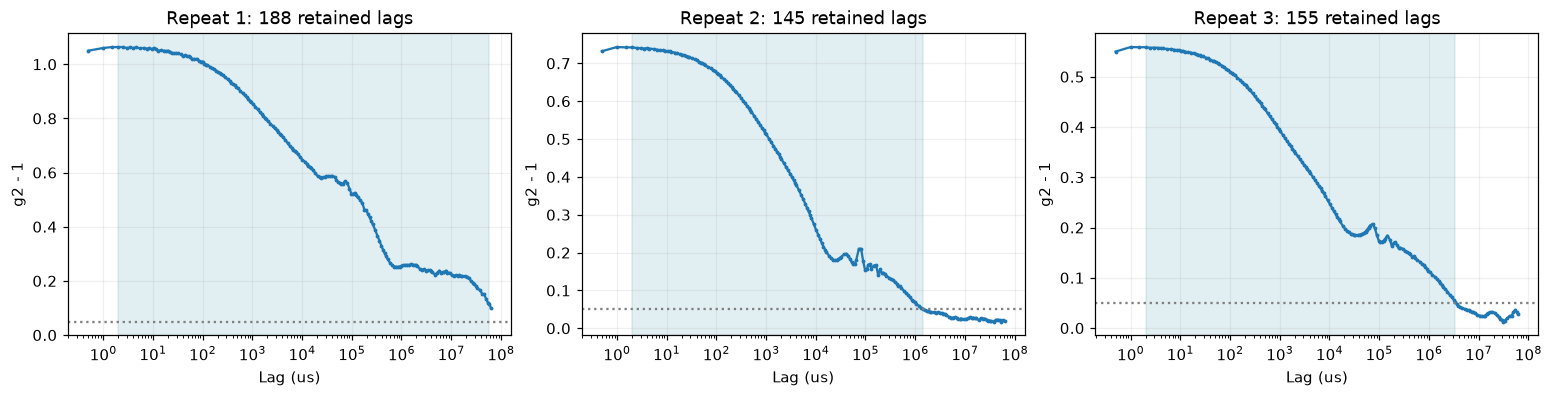

In [2]:
fig,axes=plt.subplots(1,3,figsize=(14,3.5),layout='constrained')
for i,ax in enumerate(axes):
 tt,gg=select_lags(t[i],g[i]);ax.semilogx(t[i],g[i],'.-',ms=3);ax.axvspan(tt[0],tt[-1],color='#167d9a',alpha=.12);ax.axhline(.05,color='gray',ls=':');ax.set(title=f'Repeat {i+1}: {len(tt)} retained lags',xlabel='Lag (us)',ylabel='g2 - 1');ax.grid(alpha=.2)
plt.show()

## Physics
For the three-dimensional MSD $M$, the Gaussian displacement characteristic function is $g_1=\exp(-q^2M/6)$ and the Siegert relation is $c=\beta g_1^2$. The scattering magnitude is $q=4\pi n\sin(\theta/2)/\lambda$. All symbols use the public units above. The displacement inversion is $M=-6\log(g_1)/q^2$.

Local power-law continuation uses $\alpha=d\log M/d\log t$ and angular frequency $\omega=10^6/t$. With tracer radius $a$ in nm, $|G^*|=k_BT10^{27}/[\pi aM\Gamma(1+\alpha)]$, $G'=|G^*|\cos(\pi\alpha/2)$ and $G''=|G^*|\sin(\pi\alpha/2)$. This rests on fluctuation-dissipation, an ergodic material, single scattering, and a continuum around the probe. A Brownian viscous liquid gives $G''=\eta\omega$ and $G'=0$; a constant MSD gives an elastic plateau. These limits are independently unit-tested.

## Method
Fit a stretched exponential to short-lag correlation using leave-one-out selection among nine windows. Preserve the author’s unconditional early-window fit replacement. Invert the Siegert relation, then estimate MSD and its slope using Gaussian-weighted log-linear regression. Compute both signed modulus components with the local power-law formula. No upstream package is imported. The complete three-repeat reconstruction is active in the next cell.

In [3]:
start=time.perf_counter();submission,rows=reconstruct(t,g);runtime=time.perf_counter()-start
np.savez_compressed('output/reconstruction.npz',**submission)
np.savez_compressed('notebooks/reference_outputs/fresh_cleaned_measurements.npz',**submission)
proc=subprocess.run([sys.executable,'evaluation/judge.py','--prediction','output/reconstruction.npz','--report','output/judge_report.json'],capture_output=True,text=True)
assert proc.returncode==0,proc.stderr
report=json.loads(Path('output/judge_report.json').read_text())
print('Fresh complete reconstruction runtime (s):',runtime)
print(json.dumps(report,indent=2))

Fresh complete reconstruction runtime (s): 0.1319187000626698
{
  "status": "pass",
  "passed": true,
  "metrics": {
    "storage_ncc": 0.9999999999999999,
    "storage_nrmse": 9.710939121596083e-15,
    "loss_ncc": 0.9999999999999998,
    "loss_nrmse": 1.1269864297687997e-15,
    "msd_ncc": 1.0,
    "msd_nrmse": 1.3112699068683866e-13,
    "exponent_ncc": 0.9999999999999999,
    "exponent_nrmse": 4.919239893080726e-14,
    "intercept_relative_error": 0.0,
    "forward_rmse": 0.01566838244616441
  },
  "thresholds": {
    "storage_ncc": {
      "comparison": ">=",
      "boundary": 0.999999
    },
    "storage_nrmse": {
      "comparison": "<=",
      "boundary": 1e-05
    },
    "loss_ncc": {
      "comparison": ">=",
      "boundary": 0.999999
    },
    "loss_nrmse": {
      "comparison": "<=",
      "boundary": 1e-05
    },
    "msd_ncc": {
      "comparison": ">=",
      "boundary": 0.999999
    },
    "msd_nrmse": {
      "comparison": "<=",
      "boundary": 1e-05
    },
    "ex

## Results
Solid and dashed modulus lines distinguish storage and loss. Raw MSD dots and smooth curves expose smoothing effects. Forward residuals are measured against observed correlations, not an archived fit. The CV panel shows data-driven short-lag window selection. Signed negative storage estimates are diagnosed below rather than silently clipped in saved output.

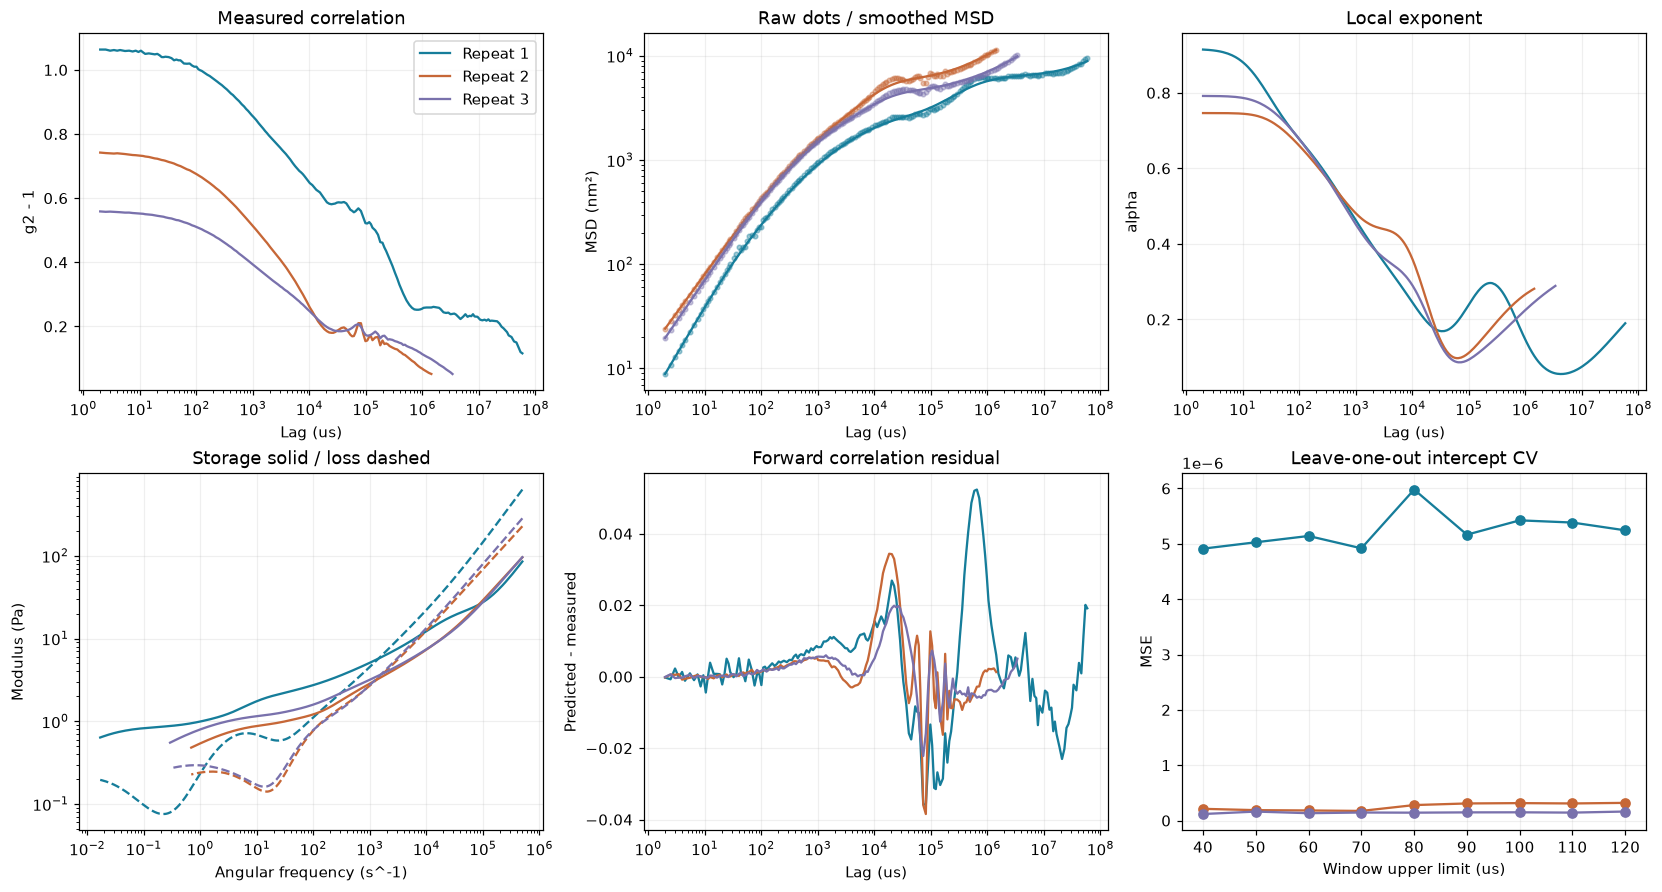

Repeat 1 intercept 1.0654601570500384 window [ 2. 40.] negative storage count 0
Repeat 2 intercept 0.7461420065522366 window [ 2. 70.] negative storage count 0
Repeat 3 intercept 0.5611106092817767 window [ 2. 40.] negative storage count 0


In [4]:
fig=diagnostic_figure(rows);plt.show()
for i,r in enumerate(rows):print('Repeat',i+1,'intercept',r['intercept'],'window',r['window'],'negative storage count',int(np.sum(r['storage']<0)))

### Independent upstream parity and repeat variability
The reference curves below were captured from a separate execution of original DLSuR on these same three observations before local extraction. The differences compare methods on identical data. Differences between experimental repeats measure repeat variability; neither comparison is a ground-truth error.

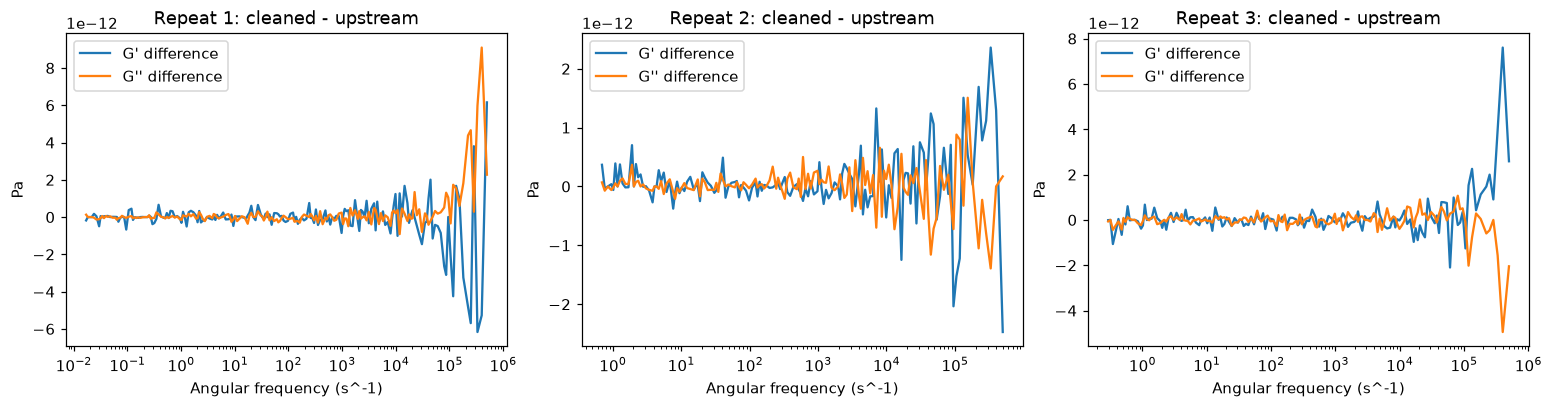

Quantity                     NCC                  dynamic-range NRMSE
reconstruction (1.0, 1.3116278038153514e-15)
msd (1.0, 1.3112699068683866e-13)
exponent (0.9999999999999999, 4.919239893080726e-14)
intercept max relative error 0.0


In [5]:
with np.load('notebooks/reference_outputs/upstream_measurements.npz') as z:up={k:z[k] for k in z.files}
fig,axes=plt.subplots(1,3,figsize=(14,3.6),layout='constrained');offset=0
for i,r in enumerate(rows):
 n=len(r['time']);ref=up['reconstruction'][0,offset:offset+n];axes[i].semilogx(r['omega'],r['storage']-ref[:,0],label="G' difference");axes[i].semilogx(r['omega'],r['loss']-ref[:,1],label="G'' difference");axes[i].set(title=f'Repeat {i+1}: cleaned - upstream',xlabel='Angular frequency (s^-1)',ylabel='Pa');axes[i].legend();offset+=n
plt.show()
print('Quantity                     NCC                  dynamic-range NRMSE')
for key in submission:
 if key=='intercept':print(key,'max relative error',np.max(abs(submission[key]/up[key]-1)))
 else:print(key,metrics(submission[key],up[key]))

### Fresh numerical comparison and ablations
Direct Laplace continuation is recomputed from the fresh MSD; finite observation limits bias its lowest/highest frequency ranges. The standard method remains local power-law inversion. Bandwidth experiments recompute the full inverse, and the half-lag experiment fits only every other reliable measurement. These are sensitivity experiments, not extra independent measurements.

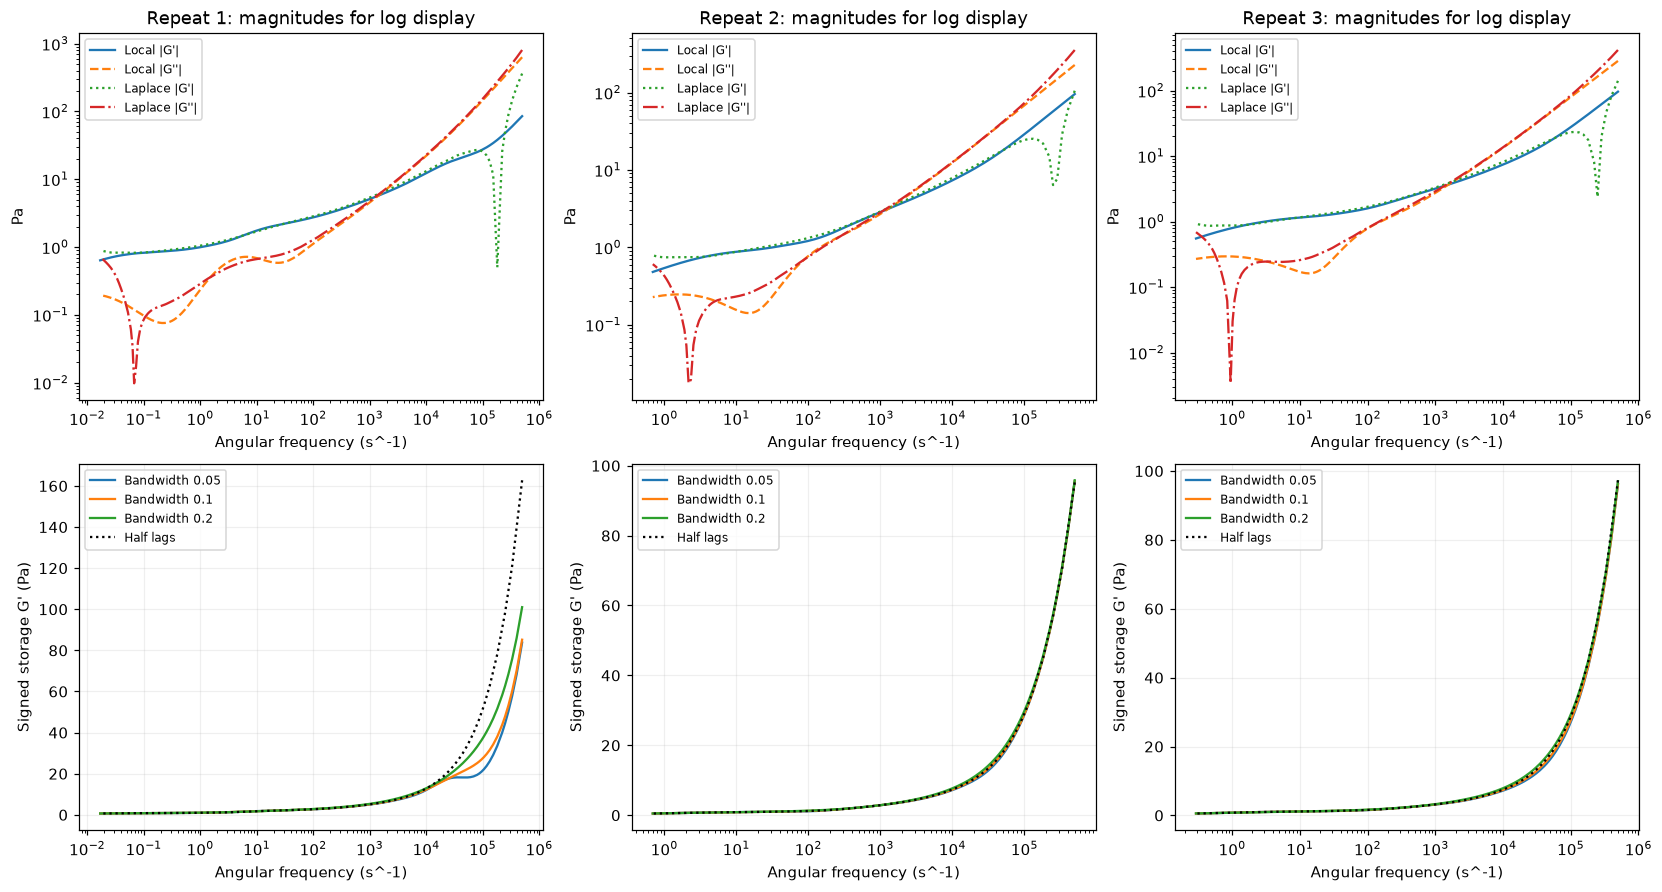

In [6]:
fig,axes=plt.subplots(2,3,figsize=(15,8),layout='constrained')
ablations={};half=[]
for i,r in enumerate(rows):
 l1,l2=laplace_alternative(r['time'],r['msd']);axes[0,i].loglog(r['omega'],abs(r['storage']),label="Local |G'|");axes[0,i].loglog(r['omega'],abs(r['loss']),'--',label="Local |G''|");axes[0,i].loglog(r['omega'],abs(l1),':',label="Laplace |G'|");axes[0,i].loglog(r['omega'],abs(l2),'-.',label="Laplace |G''|");axes[0,i].set(title=f'Repeat {i+1}: magnitudes for log display',xlabel='Angular frequency (s^-1)',ylabel='Pa');axes[0,i].legend(fontsize=8)
 for bw in [.05,.1,.2]:
  rr=reconstruct_one(t[i],g[i],bandwidth=bw);ablations[i,bw]=rr;axes[1,i].semilogx(rr['omega'],rr['storage'],label=f'Bandwidth {bw}')
 hh=reconstruct_one(t[i],g[i],stride=2);half.append(hh);axes[1,i].semilogx(hh['omega'],hh['storage'],'k:',label='Half lags');axes[1,i].set(xlabel='Angular frequency (s^-1)',ylabel="Signed storage G' (Pa)");axes[1,i].legend(fontsize=8);axes[1,i].grid(alpha=.2)
plt.show()

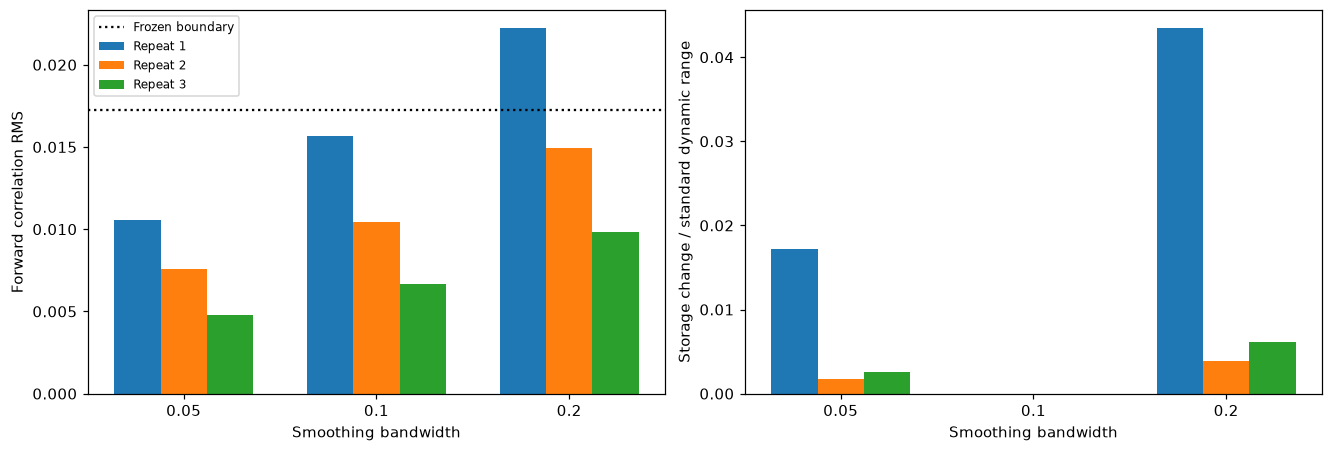

2136

In [7]:
fig,axes=plt.subplots(1,2,figsize=(12,4),layout='constrained')
labels=[];res=[];deviation=[]
for bw in [.05,.1,.2]:
 residual=[];change=[]
 for i,r in enumerate(rows):
  rr=ablations[i,bw];residual.append(np.sqrt(np.mean((correlation_forward(rr['msd'],rr['intercept'])-rr['correlation'])**2)));change.append(np.sqrt(np.mean((rr['storage']-r['storage'])**2))/np.ptp(r['storage']))
 labels.append(str(bw));res.append(residual);deviation.append(change)
x=np.arange(3)
for i in range(3):
 axes[0].bar(x+(i-1)*.24,np.array(res)[:,i],width=.24,label=f'Repeat {i+1}');axes[1].bar(x+(i-1)*.24,np.array(deviation)[:,i],width=.24)
axes[0].axhline(report['thresholds']['forward_rmse']['boundary'],ls=':',color='black',label='Frozen boundary');axes[0].legend(fontsize=8)
for ax in axes:ax.set_xticks(x,labels);ax.set_xlabel('Smoothing bandwidth')
axes[0].set_ylabel('Forward correlation RMS');axes[1].set_ylabel('Storage change / standard dynamic range');plt.show()
summary={'runtime_seconds':runtime,'judge':report,'bandwidths':labels,'residual_by_bandwidth_repeat':res,'storage_change_by_bandwidth_repeat':deviation}
Path('notebooks/reference_outputs/fresh_metrics.json').write_text(json.dumps(summary,indent=2,allow_nan=False),encoding='utf8')

## Conclusion
The fresh local calculation reproduces the independent original-method reference and passes the frozen correlation-consistency check. The experiment supports a conditional mechanical spectrum over a finite lag-derived frequency range. The comparisons show how smoothing and finite-window continuation affect the inferred response; agreement with an algorithm reference does not establish physical truth. Three repeats provide experimental variability but no independent rheometer validation for these bound files. Unknown scattering covariance, particle interactions, ergodicity and the local power-law approximation remain material limitations. No disease classification is inferred.